# 4. Sentiment model and corpus-level analysis


| | |
|---|---|
| **Reads** | def_news_AI_clean_topics.parquet, df_filtered_entities.parquet, Hugging Face dataset community-datasets/per_sent |
| **Writes** | fine-tuned model folders, pred_output_data_set.pkl |
| **Next** | end of pipeline |

**Paths:** the first code cell defines DATA_DIR: a Google Drive folder when running in Colab, <repo>/data/ when running locally (start Jupyter from the notebooks/ folder).

## 1. Packages

In [1]:
# Basic imports
import pandas as pd
import numpy as np
from torch import nn
import matplotlib.pyplot as plt
import re
import spacy
import pickle
# Enity extraction
import torch
from transformers import pipeline
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline, AutoModelForSequenceClassification, TrainingArguments, Trainer, AutoModelForTokenClassification
from transformers.pipelines.pt_utils import KeyDataset
from collections import Counter
from datasets import load_dataset
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

In [ ]:
# ---- Environment setup: works in Google Colab and locally ----
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    # Google Drive folder that holds the intermediate files (change it if yours is different)
    DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/Final Project NLP"
except ImportError:
    # Local run: intermediate files live in <repo>/data/ (start Jupyter from notebooks/)
    DATA_DIR = str(Path.cwd().parent / "data")
Path(DATA_DIR).mkdir(parents=True, exist_ok=True)
print("DATA_DIR =", DATA_DIR)


## 2. Read data

In [3]:
df_news_AI_clean_topics = pd.read_parquet(f'{DATA_DIR}/def_news_AI_clean_topics.parquet', engine='pyarrow')

In [4]:
display(df_news_AI_clean_topics.head(3))

,url,date,title,text,year,month,text_word_count,title_word_count,clean_title,clean_text,title_word_clean_count,text_word_clean_count,title_text_clean,title_text_clean_count,semantic_score,Topic_Number,Topic_Name,Probability
0,https://blockworks.co/price/bad,2025-06-23,"Bad Idea AI Price (BAD), Market Cap, Price Tod...","Bad Idea AI Price (BAD), Market Cap, Price Tod...",2025,6,483,14,"Bad Idea AI Price (BAD), Market Cap, Price Tod...",Open menuBrandsnewsletterspodcastseventsroundt...,12,470,"Bad Idea AI Price (BAD), Market Cap, Price Tod...",482,0.205120,9,Cryptocurrency & Financial Trading,0.995980
1,https://boingboing.net/2024/07/01/this-ai-vide...,2024-07-01,This AI video of gymnastics might be the freak...,\n\nThis AI video of gymnastics might be the f...,2024,7,812,15,This AI video of gymnastics might be the freak...,"\nJennifer Sandlin\n5:13 am Mon\nJul 1, 2024\n...",12,724,This AI video of gymnastics might be the freak...,736,0.282888,3,Digital Media & Entertainment,0.974883
2,https://boingboing.net/2024/09/18/if-using-ai-...,2024-09-22,"If using AI feels like a chore, try this - Boi...","\n\nIf using AI feels like a chore, try this -...",2024,9,884,12,"If using AI feels like a chore, try this","\nBoing Boing's Shop\n8:00 am Wed\nSep 18, 202...",9,802,"If using AI feels like a chore, try this \nBoi...",811,0.378478,3,Digital Media & Entertainment,0.453399


In [5]:
print('Initial dataframe shape :', df_news_AI_clean_topics.shape)
print('Columns in the dataframe :', df_news_AI_clean_topics.columns)

Initial dataframe shape : (186029, 18)
Columns in the dataframe : Index(['url', 'date', 'title', 'text', 'year', 'month', 'text_word_count',
       'title_word_count', 'clean_title', 'clean_text',
       'title_word_clean_count', 'text_word_clean_count', 'title_text_clean',
       'title_text_clean_count', 'semantic_score', 'Topic_Number',
       'Topic_Name', 'Probability'],
      dtype='object')


In [6]:
display(df_news_AI_clean_topics.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186029 entries, 0 to 186028
Data columns (total 18 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   url                     186029 non-null  object        
 1   date                    186029 non-null  datetime64[ns]
 2   title                   186029 non-null  object        
 3   text                    186029 non-null  object        
 4   year                    186029 non-null  int32         
 5   month                   186029 non-null  int32         
 6   text_word_count         186029 non-null  int64         
 7   title_word_count        186029 non-null  int64         
 8   clean_title             186029 non-null  object        
 9   clean_text              186029 non-null  object        
 10  title_word_clean_count  186029 non-null  int64         
 11  text_word_clean_count   186029 non-null  int64         
 12  title_text_clean        186029

None

In [7]:
# 1. Check for GPU (highly recommended for 50k articles)
device = 0 if torch.cuda.is_available() else -1
print(f"Using device: {'GPU' if device == 0 else 'CPU'}")

Using device: GPU


In [8]:
# Do a sample of 10% of the data to understand the process
#df_news_AI_clean_topics = df_news_AI_clean_topics.sample(frac=0.05, random_state=97)

In [9]:
# Check missing values
print('Number of missing values:', df_news_AI_clean_topics['title_text_clean'].isna().sum())
print(len(df_news_AI_clean_topics))

Number of missing values: 0
186029


## 3. Sentiment analysis

In [10]:
ds = load_dataset("community-datasets/per_sent")

In [11]:
ds

DatasetDict({
    train: Dataset({
        features: ['DOCUMENT_INDEX', 'TITLE', 'TARGET_ENTITY', 'DOCUMENT', 'MASKED_DOCUMENT', 'TRUE_SENTIMENT', 'Paragraph0', 'Paragraph1', 'Paragraph2', 'Paragraph3', 'Paragraph4', 'Paragraph5', 'Paragraph6', 'Paragraph7', 'Paragraph8', 'Paragraph9', 'Paragraph10', 'Paragraph11', 'Paragraph12', 'Paragraph13', 'Paragraph14', 'Paragraph15'],
        num_rows: 3355
    })
    test_random: Dataset({
        features: ['DOCUMENT_INDEX', 'TITLE', 'TARGET_ENTITY', 'DOCUMENT', 'MASKED_DOCUMENT', 'TRUE_SENTIMENT', 'Paragraph0', 'Paragraph1', 'Paragraph2', 'Paragraph3', 'Paragraph4', 'Paragraph5', 'Paragraph6', 'Paragraph7', 'Paragraph8', 'Paragraph9', 'Paragraph10', 'Paragraph11', 'Paragraph12', 'Paragraph13', 'Paragraph14', 'Paragraph15'],
        num_rows: 579
    })
    test_fixed: Dataset({
        features: ['DOCUMENT_INDEX', 'TITLE', 'TARGET_ENTITY', 'DOCUMENT', 'MASKED_DOCUMENT', 'TRUE_SENTIMENT', 'Paragraph0', 'Paragraph1', 'Paragraph2', 'Paragraph3',

In [12]:
# Note: This dataset only comes with a "train" split.
train_dataset = ds["train"]
test_dataset = ds["test_fixed"]
oot_dataset = ds['test_random']
# rename target column
train_dataset = train_dataset.rename_column("TRUE_SENTIMENT", "labels")
test_dataset = test_dataset.rename_column("TRUE_SENTIMENT", "labels")
oot_dataset = oot_dataset.rename_column("TRUE_SENTIMENT", "labels")

In [13]:
# Check the lenght of the train and test datasets
print(f"Train dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")
print(f"Test dataset size: {len(oot_dataset)}")

Train dataset size: 3355
Test dataset size: 827
Test dataset size: 579


,proportion
labels,
2,0.523994
1,0.371386
0,0.104620


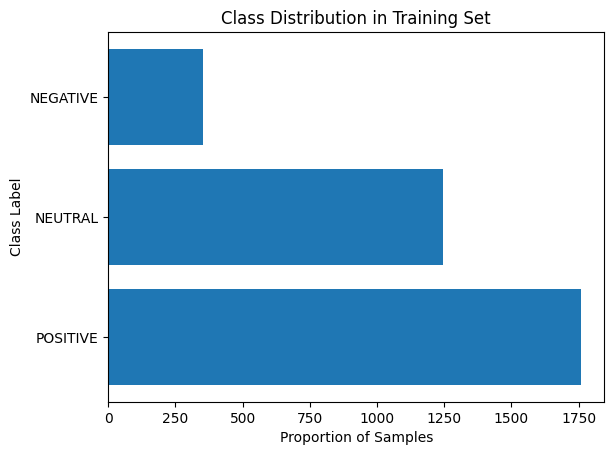

In [14]:
# example to view the class distribution in the dataset
df_aux = train_dataset.to_pandas()

display(df_aux["labels"].value_counts(normalize=True))

values = df_aux["labels"].value_counts().values
class_labels = df_aux["labels"].value_counts().index
replacement_map = {0: 'NEGATIVE', 1: 'NEUTRAL', 2:'POSITIVE'}
# Create a new list using the map
class_labels = [replacement_map.get(item, item) for item in class_labels]

plt.title("Class Distribution in Training Set")
plt.barh(class_labels, values)
plt.xlabel("Proportion of Samples")
plt.ylabel("Class Label")
plt.show()

## 3. Tune model distilbert-base

### 3.1 Model with unbalance weight

In [15]:
model_checkpoint = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=3)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [16]:
def tokenize_function(examples):
    return tokenizer(examples["DOCUMENT"], padding="max_length", truncation=True)

# Apply tokenizer
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)
tokenized_oot = oot_dataset.map(tokenize_function, batched=True)

In [17]:
#  Define your label mappings (highly recommended for 3-class models)
id2label = {0: "NEGATIVE", 1: "NEUTRAL", 2: "POSITIVE"}
label2id = {"NEGATIVE": 0, "NEUTRAL": 1, "POSITIVE": 2}

In [18]:
def compute_metrics(pred):
    """
    Calcualtes accuracy and f1 score given predictions.

    Args:
        pred (EvalPrediction):
    """
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    f1 = f1_score(labels, preds, average="weighted")
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "f1": f1}

In [19]:
file_path = f"{DATA_DIR}/traning_args_no_weight"


# Train arguments
training_args = TrainingArguments(
    output_dir=file_path,
    learning_rate=2e-5,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    eval_strategy="epoch"
)
# train the model
trainer = Trainer(
model=model,
args=training_args,
train_dataset=tokenized_train,
eval_dataset=tokenized_test,
compute_metrics=compute_metrics,
)

In [20]:
# save the tunning model
file_path = f"{DATA_DIR}/article_sentiment_results_no_weight"

# Save the model's weights and configuration
trainer.save_model(file_path)

# Save the tokenizer alongside the model
tokenizer.save_pretrained(file_path)

print(f"Model and tokenizer successfully saved to {file_path}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer successfully saved to /content/drive/MyDrive/Colab Notebooks/Final Project NLP/article_sentiment_results_no_weight


In [21]:
# Check error metrics Train, Validation and Test
pred_output_train = trainer.predict(tokenized_train)
pred_output_test = trainer.predict(tokenized_test)
pred_output_oot = trainer.predict(tokenized_oot)

In [22]:
# Compare error metrics in different datasets
df_metrics_train = pd.DataFrame([pred_output_train.metrics])
df_metrics_train['dataset'] = 'train'
df_metrics_val = pd.DataFrame([pred_output_test.metrics])
df_metrics_val['dataset'] = 'test'
df_metrics_test = pd.DataFrame([pred_output_oot.metrics])
df_metrics_test['dataset'] = 'oot'

# Combine dataframes
df_metrics = pd.concat([df_metrics_train, df_metrics_val, df_metrics_test], ignore_index=True)
display(df_metrics)

,test_loss,test_model_preparation_time,test_accuracy,test_f1,test_runtime,test_samples_per_second,test_steps_per_second,dataset
0,1.158672,0.0014,0.104620,0.020367,4.6277,724.988,11.453,train
1,1.144123,0.0014,0.168077,0.048370,1.0996,752.069,11.822,test
2,1.152822,0.0014,0.126079,0.028233,0.7765,745.688,12.879,oot


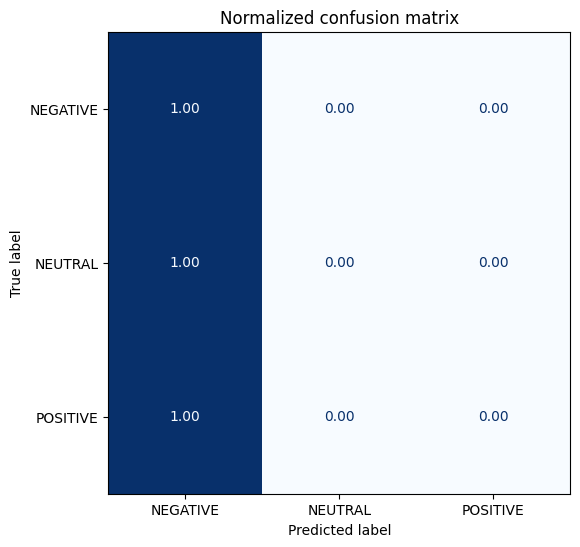

In [23]:
def plot_confusion_matrix(y_preds, y_true, labels):
  cm = confusion_matrix(y_true, y_preds, normalize="true")
  fig, ax = plt.subplots(figsize=(6, 6))
  disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
  disp.plot(cmap="Blues", values_format=".2f", ax=ax, colorbar=False)
  plt.title("Normalized confusion matrix")
  plt.show()

# Confusion matrix test
id2label = {0: "NEGATIVE", 1: "NEUTRAL", 2: "POSITIVE"}
y_test = np.array(tokenized_test["labels"])
y_pred = pred_output_test.predictions.argmax(axis=1)
plot_confusion_matrix(y_pred, y_test, list(id2label.values()))

### 3.2 Model with balance weight

In [24]:
run = True

if run:
  # --- 1. Calculate the Class Weights ---

  # Extract all the true labels from your training dataset
  train_labels = np.array(tokenized_train["labels"])

  # Use Scikit-Learn to calculate the balanced weights automatically
  class_weights = compute_class_weight(
      class_weight="balanced",
      classes=np.unique(train_labels),
      y=train_labels
  )

  # Convert the weights to a PyTorch tensor and push to your GPU (if available)
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

  print(f"Calculated Class Weights: {weights_tensor}")


  # --- 2. Build the Custom Trainer ---

  class WeightedTrainer(Trainer):
      def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
          # Extract the true labels from the batch
          labels = inputs.pop("labels")

          # Pass the text inputs through the model to get its predictions (logits)
          outputs = model(**inputs)
          logits = outputs.get("logits")

          # Apply the weighted Cross Entropy Loss
          loss_fct = nn.CrossEntropyLoss(weight=weights_tensor)

          # Calculate the actual loss
          loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))

          return (loss, outputs) if return_outputs else loss


  # --- 3. Initialize and Train ---

  # Your existing model initialization
  model = AutoModelForSequenceClassification.from_pretrained(
      model_checkpoint,
      num_labels=3,
      id2label=id2label,
      label2id=label2id
  )

  file_path = f"{DATA_DIR}/traning_args_weight"

  # Your existing arguments
  training_args = TrainingArguments(
      output_dir=file_path,
      learning_rate=2e-5,
      per_device_train_batch_size=256,
      per_device_eval_batch_size=256,
      num_train_epochs=3,
      weight_decay=0.01,
      eval_strategy="epoch",
  )

  # Use your new WeightedTrainer instead of the default Trainer
  trainer = WeightedTrainer(
      model=model,
      args=training_args,
      train_dataset=tokenized_train,
      eval_dataset=tokenized_test,
      compute_metrics=compute_metrics,
  )

  trainer.train()

# save the tunning model
file_path = f"{DATA_DIR}/article_sentiment_results_weight"

# Save the model's weights and configuration
trainer.save_model(file_path)

# Save the tokenizer alongside the model
tokenizer.save_pretrained(file_path)

print(f"Model and tokenizer successfully saved to {file_path}")

Calculated Class Weights: tensor([3.1861, 0.8975, 0.6361], device='cuda:0')


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,1.096295,0.405079,0.339132
2,No log,1.067793,0.268440,0.248338
3,No log,1.066920,0.313180,0.316655


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer successfully saved to /content/drive/MyDrive/Colab Notebooks/Final Project NLP/article_sentiment_results_weight


In [25]:
# save the tunning model
file_path = f"{DATA_DIR}/article_sentiment_results_weight_V2"

# Save the model's weights and configuration
trainer.save_model(file_path)

# Save the tokenizer alongside the model
tokenizer.save_pretrained(file_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/Colab Notebooks/Final Project NLP/article_sentiment_results_weight_V2/tokenizer_config.json',
 '/content/drive/MyDrive/Colab Notebooks/Final Project NLP/article_sentiment_results_weight_V2/tokenizer.json')

In [26]:
save_directory = f"{DATA_DIR}/article_sentiment_results_weight"

# Load your custom fine-tuned model
my_loaded_model = AutoModelForSequenceClassification.from_pretrained(save_directory)

# Load your matching tokenizer
my_loaded_tokenizer = AutoTokenizer.from_pretrained(save_directory)

# 3. Create a new Trainer instance specifically for evaluation/prediction
#eval_trainer = Trainer(model=my_loaded_model)
eval_trainer = trainer

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [27]:
# Check error metrics Train, Validation and Test
pred_output_train = eval_trainer.predict(tokenized_train)
pred_output_test = eval_trainer.predict(tokenized_test)
pred_output_oot = eval_trainer.predict(tokenized_oot)

In [28]:
# Compare error metrics in different datasets
df_metrics_train = pd.DataFrame([pred_output_train.metrics])
df_metrics_train['dataset'] = 'train'
df_metrics_val = pd.DataFrame([pred_output_test.metrics])
df_metrics_val['dataset'] = 'test'
df_metrics_test = pd.DataFrame([pred_output_oot.metrics])
df_metrics_test['dataset'] = 'oot'

# Combine dataframes
df_metrics = pd.concat([df_metrics_train, df_metrics_val, df_metrics_test], ignore_index=True)
display(df_metrics)

,test_loss,test_accuracy,test_f1,test_runtime,test_samples_per_second,test_steps_per_second,dataset
0,1.005299,0.470939,0.472465,4.1948,799.791,3.337,train
1,1.066920,0.313180,0.316655,1.0373,797.299,3.856,test
2,1.012263,0.449050,0.443490,0.7308,792.294,4.105,oot


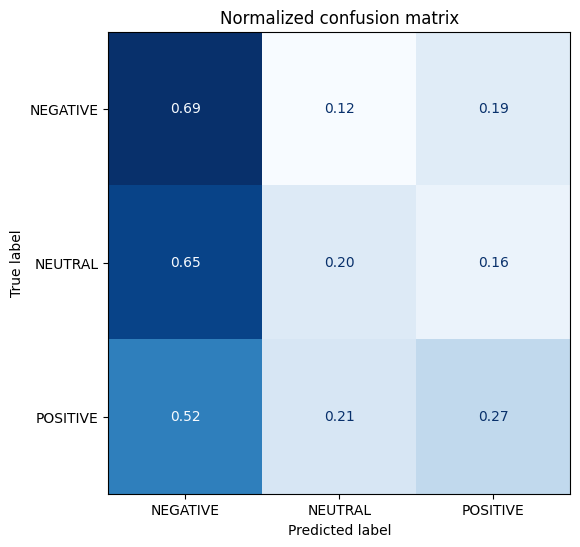

In [29]:
def plot_confusion_matrix(y_preds, y_true, labels):
  cm = confusion_matrix(y_true, y_preds, normalize="true")
  fig, ax = plt.subplots(figsize=(6, 6))
  disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
  disp.plot(cmap="Blues", values_format=".2f", ax=ax, colorbar=False)
  plt.title("Normalized confusion matrix")
  plt.show()

# Confusion matrix test
id2label = {0: "NEGATIVE", 1: "NEUTRAL", 2: "POSITIVE"}
y_test = np.array(tokenized_test["labels"])
y_pred = pred_output_test.predictions.argmax(axis=1)
plot_confusion_matrix(y_pred, y_test, list(id2label.values()))

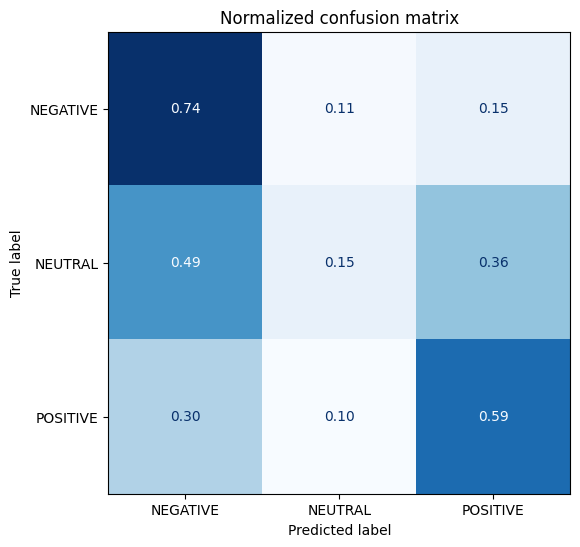

In [30]:
# Confusion matrix test
id2label = {0: "NEGATIVE", 1: "NEUTRAL", 2: "POSITIVE"}
y_oot = np.array(tokenized_oot["labels"])
y_pred = pred_output_oot.predictions.argmax(axis=1)
plot_confusion_matrix(y_pred, y_oot, list(id2label.values()))

## 4. Estimate Sentiment topic level

 Do the prediction in the total dataset by topic

In [31]:
# Convert the DataFrame to a Hugging Face Dataset
hf_dataset = Dataset.from_pandas(df_news_AI_clean_topics)
# 3. Verify the conversion
print(hf_dataset)

Dataset({
    features: ['url', 'date', 'title', 'text', 'year', 'month', 'text_word_count', 'title_word_count', 'clean_title', 'clean_text', 'title_word_clean_count', 'text_word_clean_count', 'title_text_clean', 'title_text_clean_count', 'semantic_score', 'Topic_Number', 'Topic_Name', 'Probability'],
    num_rows: 186029
})


In [32]:
# Change column name
hf_dataset = hf_dataset.rename_column("title_text_clean", "DOCUMENT")
# Apply tokenizer
def tokenize_function_trainer(examples):
    return my_loaded_tokenizer(examples["DOCUMENT"], padding="max_length", truncation=True)

tokenized_df_AI = hf_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/186029 [00:00<?, ? examples/s]

In [33]:
# Check error metrics Train, Validation and Test
pred_output_data_set = eval_trainer.predict(tokenized_df_AI)

In [34]:
# Export the sentimenal predeictions as a pickle
file_path = f"{DATA_DIR}/pred_output_data_set.pkl"
# Save lemmatization text
with open(file_path, "wb") as f:
  pickle.dump(pred_output_data_set, f)
  print(f"Successfully saved to {file_path}")

Successfully saved to /content/drive/MyDrive/Colab Notebooks/Final Project NLP/pred_output_data_set.pkl


In [35]:
len(pred_output_data_set.predictions.argmax(axis=1))

186029

In [36]:
max_pred_by_row =  pred_output_data_set.predictions.argmax(axis=1)

In [37]:
# Save results
df_news_AI_clean_topics['sentiment_topic'] = pred_output_data_set.predictions.argmax(axis=1)

In [38]:
display(df_news_AI_clean_topics['sentiment_topic'].value_counts(normalize=True))

,proportion
sentiment_topic,
2,0.908090
0,0.071381
1,0.020529


In [39]:
values = df_news_AI_clean_topics['sentiment_topic'].value_counts().reset_index()
value_list = values['count'].values
sentiment_topic = values['sentiment_topic'].values
replacement_map = {0: 'NEGATIVE', 1: 'NEUTRAL', 2:'POSITIVE'}
print(value_list)
print(sentiment_topic)

[168931  13279   3819]
[2 0 1]


,sentiment_topic,count
0,2,168931
1,0,13279
2,1,3819


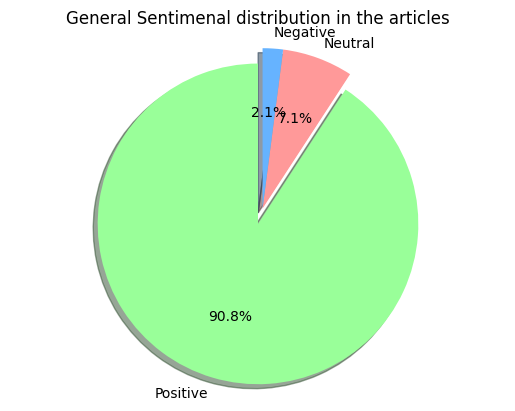

,sentiment_topic,count
0,2,14786
1,0,224
2,1,91


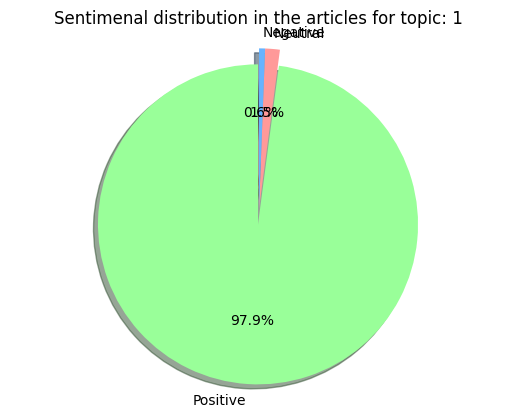

,sentiment_topic,count
0,2,12105
1,0,4076
2,1,837


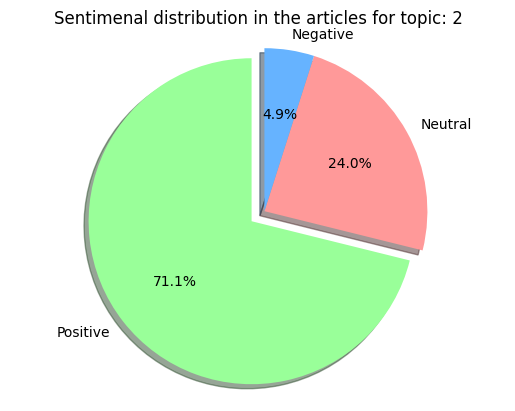

,sentiment_topic,count
0,2,14994
1,0,478
2,1,266


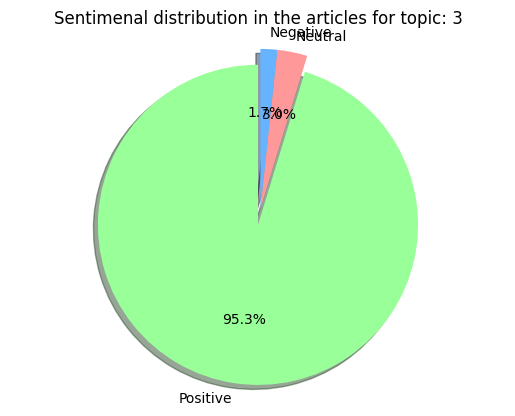

,sentiment_topic,count
0,2,16248
1,0,1632
2,1,306


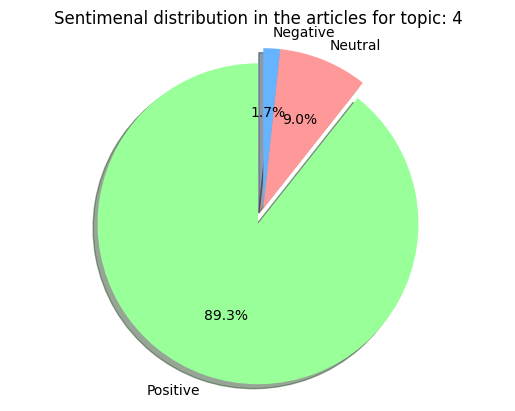

,sentiment_topic,count
0,2,18312
1,0,1516
2,1,615


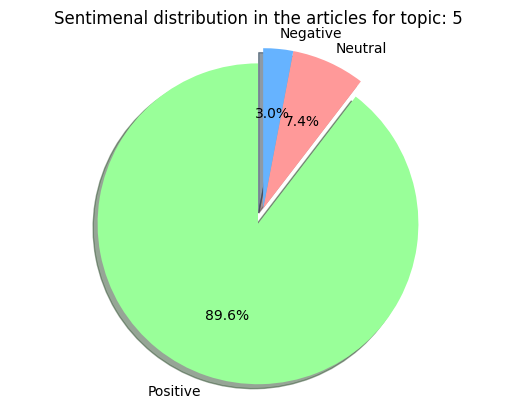

,sentiment_topic,count
0,2,16880
1,0,2249
2,1,271


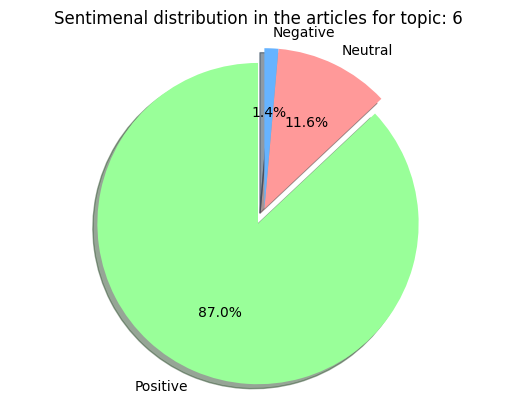

,sentiment_topic,count
0,2,12665
1,0,1123
2,1,596


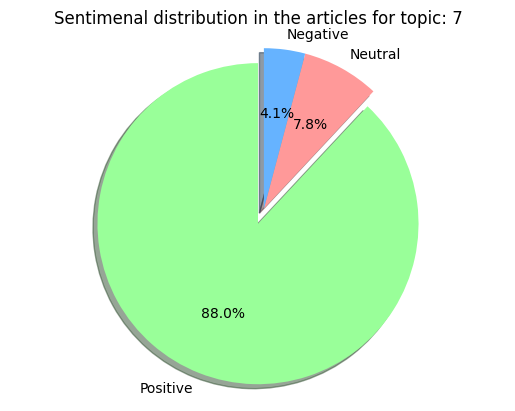

,sentiment_topic,count
0,2,20262
1,0,1681
2,1,734


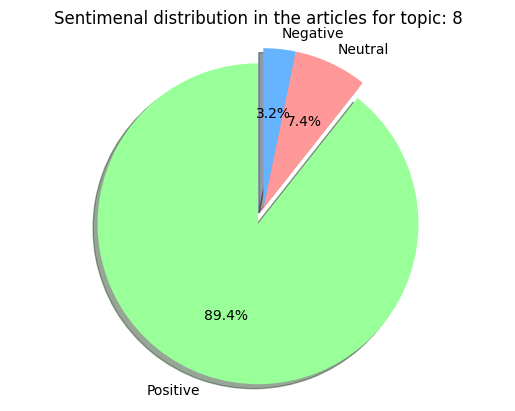

,sentiment_topic,count
0,2,33473
1,0,93
2,1,51


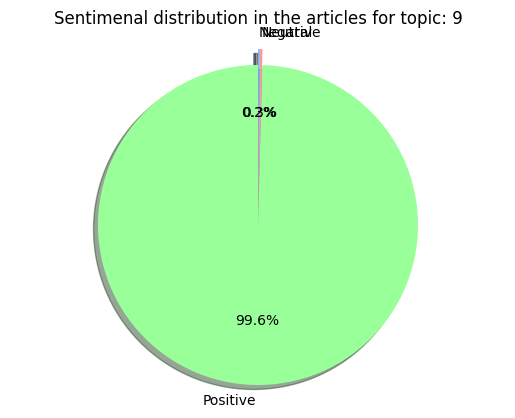

,sentiment_topic,count
0,2,9206
1,0,207
2,1,52


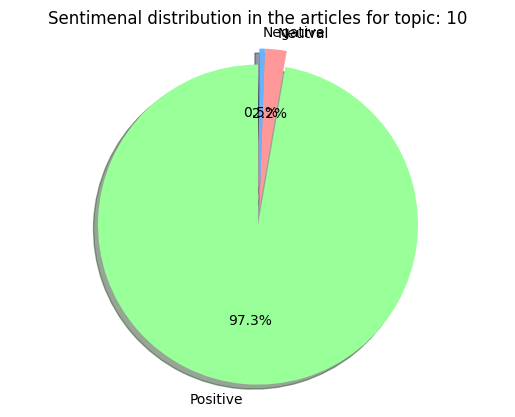

In [40]:
def pie_chart(value_list, title, No_filtre=True, topic=0):
  if No_filtre:
    values = df_news_AI_clean_topics['sentiment_topic'].value_counts().reset_index()
    value_list = values['count'].values
    sentiment_topic = values['sentiment_topic'].values
    display(values)
  else:
    df_aux = df_news_AI_clean_topics[df_news_AI_clean_topics['Topic_Number']==topic]
    values = df_aux['sentiment_topic'].value_counts().reset_index()
    value_list = values['count'].values
    sentiment_topic = values['sentiment_topic'].values
    display(values)



  # Plot pie chart
  # 1. Prepare the data
  labels = ['Positive', 'Neutral', 'Negative']
  colors = ['#99ff99','#ff9999', '#66b3ff']

  # 2. Highlight a specific slice (optional)
  # The '0.1' pulls the 'Python' slice out slightly. The others (0) stay in place.
  explode = (0.1, 0, 0)

  # 3. Create the pie chart
  plt.pie(value_list,
            explode=explode,
            labels=labels,
            colors=colors,
            autopct='%1.1f%%', # Formats the percentages to one decimal place
            shadow=True,       # Adds a drop shadow
            startangle=90)     # Rotates the start of the chart by 90 degrees

  # 4. Add a title and ensure it's a perfect circle
  plt.title(title)
  plt.axis('equal') # Equal aspect ratio ensures the pie is drawn as a circle.

  # 5. Display the plot
  plt.show()


pie_chart(value_list, 'General Sentimenal distribution in the articles')

for i in range(0,10):
  title = 'Sentimenal distribution in the articles for topic: ' + str(i+1)
  pie_chart(value_list, title, False, i)

## 4. Estimate Sentiment entity level

In [41]:
df_filtered_entities = pd.read_parquet(f'{DATA_DIR}/df_filtered_entities.parquet', engine='pyarrow')

In [42]:
df_filtered_entities.head()

,index_doc,word,entity,frenqency
0,0,"[##B, ##works Research, BA]","[ORG, ORG, ORG]","[1, 1, 1]"
1,1,"[Werner, Dream Machine]","[ORG, PRODUCT]","[1, 1]"
2,2,"[this Boing Boing ' s Shop, Cha, GPT - 4, Goog...","[ORG, ORG, PRODUCT, ORG, PRODUCT, ORG, PRODUCT...","[1, 1, 2, 2, 1, 1, 1, 1, 1]"
3,3,"[Fund, de China, China, Baidu]","[ORG, ORG, ORG, ORG]","[1, 1, 1, 1]"
4,4,"[Microsoft, ##vidia, Empower Develo, Windows A...","[ORG, ORG, ORG, PRODUCT, PRODUCT, PRODUCT, ORG...","[8, 3, 1, 5, 1, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, ..."


In [43]:
# Merge both dataframe
initial_rows = len(df_news_AI_clean_topics)
df_news_AI_entity = df_news_AI_clean_topics.copy()
df_news_AI_entity['index'] = df_news_AI_clean_topics.index
df_news_AI_entity = pd.merge(df_news_AI_entity, df_filtered_entities, left_on='index', right_on='index_doc', how='inner')
final_rows = len(df_news_AI_entity)
print(f'Initial rows: {initial_rows}, Final rows: {final_rows}')

Initial rows: 186029, Final rows: 186029


In [44]:
# Top 20 most common entities
df_exploded = df_news_AI_entity.explode(['word', 'entity', 'frenqency'])

# 2. Ensure the frequency column is treated as numeric integers
df_exploded['frenqency'] = pd.to_numeric(df_exploded['frenqency'])

# 3. Group by 'word' and 'entity', sum the frequencies
frenq_entities = (df_exploded
                   .groupby(['word', 'entity'], as_index=False).agg({'frenqency':'sum','sentiment_topic':'mean'})
                   .sort_values(by='frenqency', ascending=False))



# 4. Reset the index for a clean output
frenq_entities = frenq_entities.reset_index(drop=True)
#total
total = frenq_entities['frenqency'].sum()
frenq_entities['percentage'] = frenq_entities['frenqency'] / total * 100

display(frenq_entities)

,word,entity,frenqency,sentiment_topic,percentage
0,Google,ORG,53603.0,1.804636,2.298477
1,Microsoft,ORG,51985.0,1.752800,2.229098
2,OpenAI,ORG,50664.0,1.599978,2.172454
3,AI,ORG,38622.0,1.826020,1.656098
4,Cha,ORG,35735.0,1.654805,1.532304
...,...,...,...,...,...
236313,E + D (,ORG,1.0,2.000000,0.000043
236314,E - 208,PRODUCT,1.0,2.000000,0.000043
236315,E - 7,PRODUCT,1.0,2.000000,0.000043
236316,E - A,PRODUCT,1.0,2.000000,0.000043


,word,entity,frenqency,sentiment_topic
0,Google,ORG,53603.0,1.804636
1,Microsoft,ORG,51985.0,1.752800
2,OpenAI,ORG,50664.0,1.599978
3,AI,ORG,38622.0,1.826020
4,Apple,ORG,26393.0,1.840489
5,Open,ORG,25089.0,1.650529
6,PR,ORG,24688.0,1.983859
7,Amazon,ORG,15926.0,1.843518
8,Nvidia,ORG,15313.0,1.856473
9,PRNewswire,ORG,12920.0,1.994381


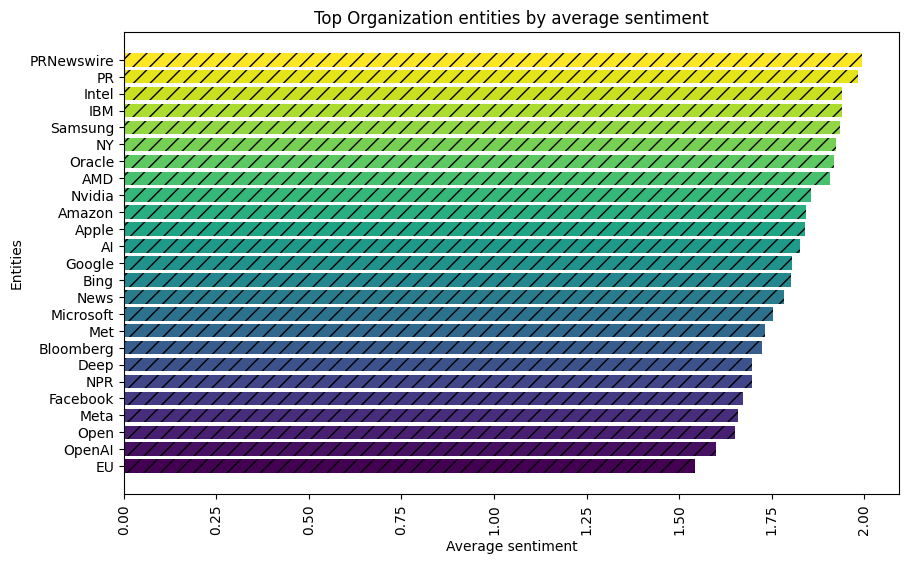

In [45]:
# Filter only ORG
df_aux = frenq_entities[frenq_entities['entity']=='ORG'].copy()
df_aux['word'] = df_aux['word'].str.replace('##vidia', 'Nvidia')
df_aux = df_aux.groupby(['word','entity']).agg({'frenqency':'sum','sentiment_topic':'mean'}).reset_index()
df_aux = df_aux.sort_values(by='frenqency', ascending=False)

# Remove noise entities
df_aux = df_aux[df_aux['word']!='##I']
df_aux = df_aux[df_aux['word']!='ME']
df_aux = df_aux[df_aux['word']!='Re']
df_aux = df_aux[df_aux['word']!='An']
df_aux = df_aux[df_aux['word']!='PRNews']
df_aux = df_aux[df_aux['word']!='In']
df_aux = df_aux[df_aux['word']!='Cha']
df_aux.reset_index(drop=True, inplace=True)


df_aux = df_aux.head(25)
display(df_aux)

df_aux = df_aux.sort_values(by='sentiment_topic', ascending=True)

num_bars = len(df_aux['word'])
color_gradient = plt.cm.viridis(np.linspace(0, 1, num_bars))
plt.figure(figsize=(10, 6))
# Create the vertical bar plot with colors and a hatch pattern
bars = plt.barh(
    df_aux['word'],
    df_aux['sentiment_topic'],
    color=color_gradient,
    hatch='//' )

plt.title("Top Organization entities by average sentiment")
plt.xlabel("Average sentiment")
plt.ylabel("Entities")
plt.xticks(rotation=90)
plt.show()

,word,entity,frenqency,sentiment_topic
0,Gemini,PRODUCT,6170.0,1.875613
1,Cha,PRODUCT,4841.0,1.807777
2,GP,PRODUCT,3937.0,1.935620
3,AI,PRODUCT,3365.0,1.954237
4,GPT - 4,PRODUCT,2602.0,1.859438
5,iPhone,PRODUCT,1355.0,1.951351
6,GPU,PRODUCT,1020.0,1.926332
7,Windows 11,PRODUCT,961.0,1.966581
8,Bing,PRODUCT,892.0,1.964824
9,##AI,PRODUCT,880.0,1.927769


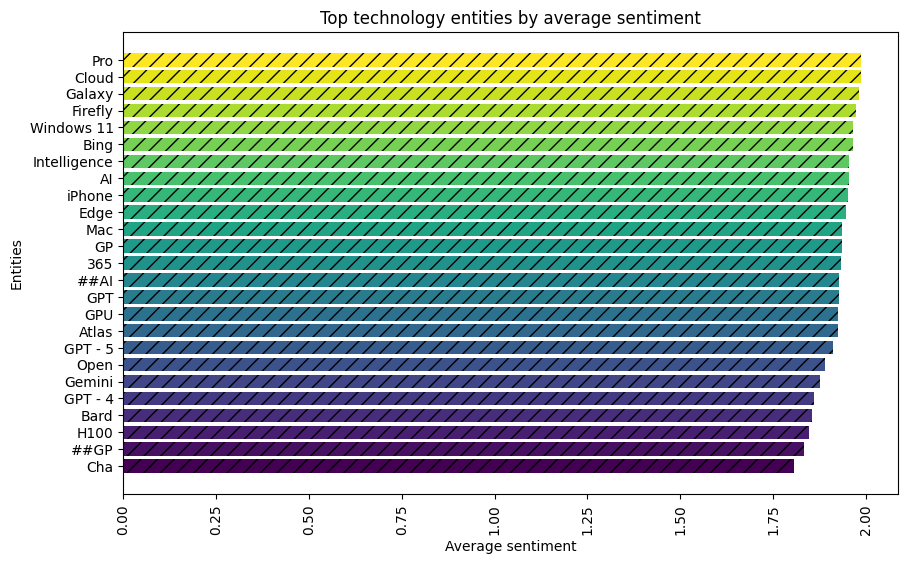

In [46]:
# Filter only ORG
df_aux = frenq_entities[frenq_entities['entity']=='PRODUCT'].copy()
df_aux['word'] = df_aux['word'].str.replace('##vidia', 'Nvidia')
df_aux = df_aux.groupby(['word','entity']).agg({'frenqency':'sum','sentiment_topic':'mean'}).reset_index()
df_aux = df_aux.sort_values(by='frenqency', ascending=False)

# Remove noise entities
df_aux = df_aux[df_aux['word']!='##I']
df_aux = df_aux[df_aux['word']!='##t']
df_aux = df_aux[df_aux['word']!='the']
df_aux = df_aux[df_aux['word']!='##lot']
df_aux = df_aux[df_aux['word']!='##lot']
df_aux = df_aux[df_aux['word']!='##3']
df_aux = df_aux[df_aux['word']!='##T']
df_aux = df_aux[df_aux['word']!='Pi']
df_aux = df_aux[df_aux['word']!='In']
df_aux = df_aux[df_aux['word']!='##2']
df_aux = df_aux[df_aux['word']!='##VI']
df_aux = df_aux[df_aux['word']!='Co']
df_aux = df_aux[df_aux['word']!='So']
df_aux = df_aux[df_aux['word']!='Re']
df_aux = df_aux[df_aux['word']!='##A']
df_aux.reset_index(drop=True, inplace=True)


df_aux = df_aux.head(25)
display(df_aux)

df_aux = df_aux.sort_values(by='sentiment_topic', ascending=True)

num_bars = len(df_aux['word'])
color_gradient = plt.cm.viridis(np.linspace(0, 1, num_bars))
plt.figure(figsize=(10, 6))
# Create the vertical bar plot with colors and a hatch pattern
bars = plt.barh(
    df_aux['word'],
    df_aux['sentiment_topic'],
    color=color_gradient,
    hatch='//' )

plt.title("Top technology entities by average sentiment")
plt.xlabel("Average sentiment")
plt.ylabel("Entities")
plt.xticks(rotation=90)
plt.show()

## 4. Estimate Sentiment overtime

,year,sentiment_topic
0,2022,1.927978
1,2023,1.850415
2,2024,1.809730
3,2025,1.815552


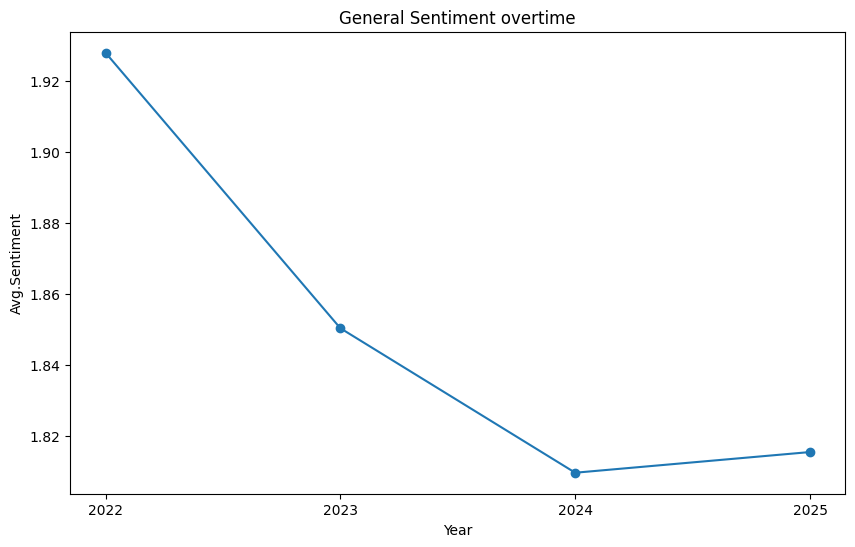

In [47]:
# Years
df_year = df_news_AI_clean_topics[df_news_AI_clean_topics['year'] != 2026]
df_year = df_year.groupby(['year']).agg({'sentiment_topic':'mean'}).reset_index()
display(df_year)

# Plot
year_list = df_year['year'].unique()
plt.figure(figsize=(10, 6))
plt.plot(df_year['year'], df_year['sentiment_topic'], marker='o', linestyle='-')
plt.title('General Sentiment overtime')
plt.xlabel('Year')
plt.ylabel('Avg.Sentiment')
plt.xticks(year_list)
plt.show()


,year,Topic_Number,sentiment_topic
0,2022,0,1.982727
1,2022,1,1.422627
2,2022,2,1.895050
3,2022,3,1.861411
4,2022,4,1.923664
5,2022,5,1.929078
6,2022,6,1.873288
7,2022,7,1.891274
8,2022,8,1.986980
9,2022,9,1.987780


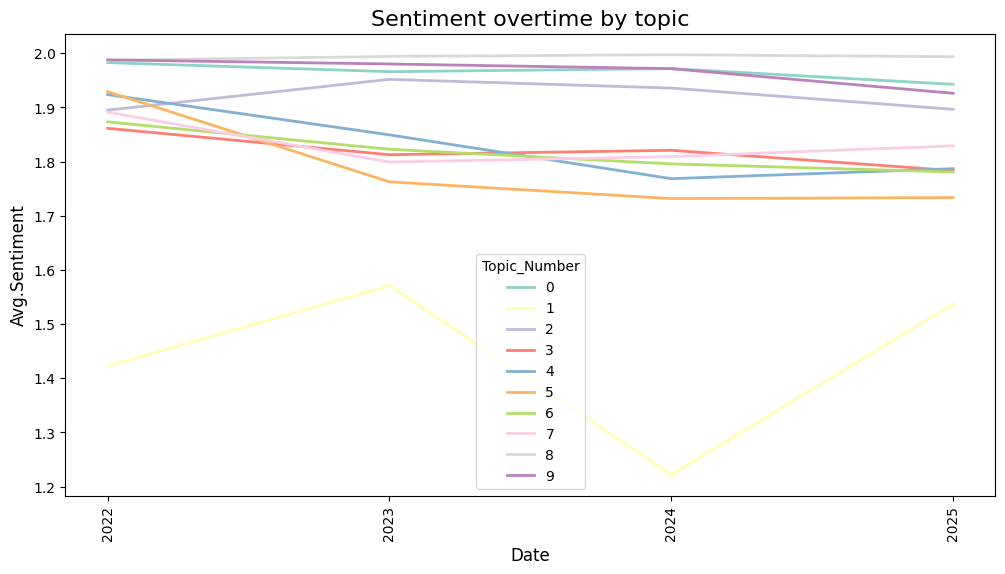

In [48]:
import seaborn as sns
# Sentiment overtime by topic
df_year_topic = df_news_AI_clean_topics[df_news_AI_clean_topics['year'] != 2026]
df_year_topic = df_year_topic.groupby(['year','Topic_Number']).agg({'sentiment_topic':'mean'}).reset_index()
display(df_year_topic.head(10))


# Plot
# 3. Create the plot
plt.figure(figsize=(12, 6)) # Set the figure size

# 4. Use Seaborn's lineplot
sns.lineplot(data=df_year_topic,
             x='year',
             y='sentiment_topic',
             hue='Topic_Number',    # Differentiates the lines by color
             palette='Set3',
             linewidth=2)

# 5. Customize the chart
plt.title('Sentiment overtime by topic', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Avg.Sentiment', fontsize=12)

# Rotate x-axis dates so they don't overlap
plt.xticks(rotation=90)
plt.xticks(year_list)

# 6. Display the plot
plt.show()


In [49]:
df_exploded = df_news_AI_entity.explode(['word', 'entity', 'frenqency'])

# 2. Ensure the frequency column is treated as numeric integers
df_exploded['frenqency'] = pd.to_numeric(df_exploded['frenqency'])

# 3. Group by 'word' and 'entity', sum the frequencies
frenq_entities_year = (df_exploded
                   .groupby(['word', 'entity','year'], as_index=False).agg({'frenqency':'sum','sentiment_topic':'mean'})
                   .sort_values(by='frenqency', ascending=False))



# 4. Reset the index for a clean output
frenq_entities_year = frenq_entities_year.reset_index(drop=True)
#total
total = frenq_entities_year['frenqency'].sum()
frenq_entities_year['percentage'] = frenq_entities_year['frenqency'] / total * 100

display(frenq_entities_year)

,word,entity,year,frenqency,sentiment_topic,percentage
0,Microsoft,ORG,2023,25842.0,1.763985,1.108096
1,Google,ORG,2023,21053.0,1.835989,0.902745
2,Cha,ORG,2023,20329.0,1.678825,0.871700
3,OpenAI,ORG,2023,20211.0,1.598712,0.866640
4,PR,ORG,2023,15812.0,1.987239,0.678013
...,...,...,...,...,...,...
313283,##0 / FM,ORG,2023,1.0,2.000000,0.000043
313284,” And Ithaca Shakespeare Company,ORG,2022,1.0,2.000000,0.000043
313285,” Associated Press,ORG,2024,1.0,2.000000,0.000043
313286,” Automotive Industries (,ORG,2024,1.0,2.000000,0.000043


,word,entity,year,frenqency,sentiment_topic
0,Microsoft,ORG,2023,25842.0,1.763985
1,Google,ORG,2023,21053.0,1.835989
2,OpenAI,ORG,2023,20211.0,1.598712
4,OpenAI,ORG,2025,15057.0,1.622317
5,Google,ORG,2024,14681.0,1.767698
6,Microsoft,ORG,2024,13902.0,1.706002
7,Google,ORG,2025,13600.0,1.806971
8,OpenAI,ORG,2024,13528.0,1.550774
10,Apple,ORG,2024,12510.0,1.884328
13,Microsoft,ORG,2025,10019.0,1.766503


<Figure size 1000x600 with 0 Axes>

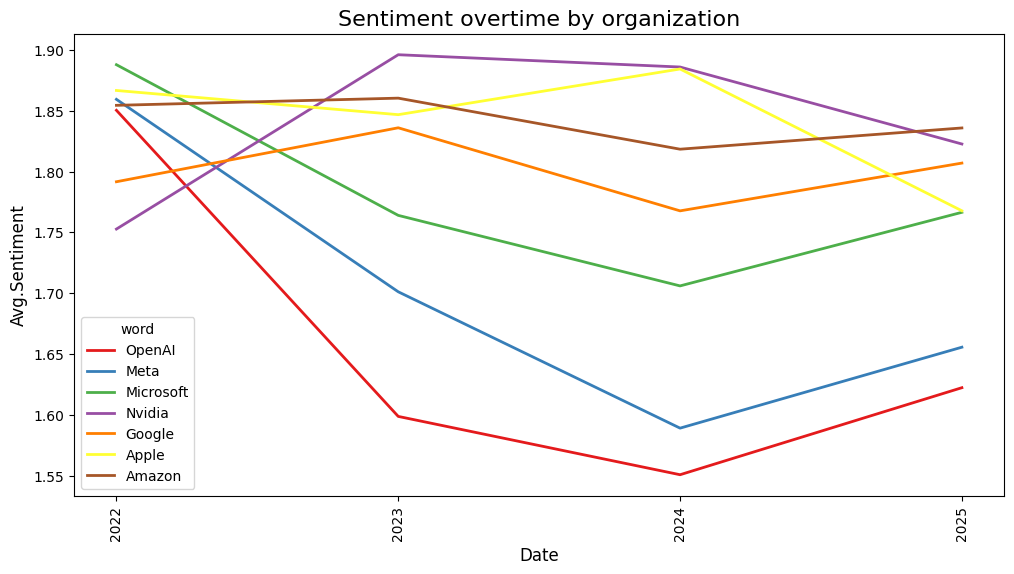

In [50]:
# Filter only ORG
df_aux = frenq_entities_year[frenq_entities_year['entity']=='ORG'].copy()
df_aux['word'] = df_aux['word'].str.replace('##vidia', 'Nvidia')
df_aux = df_aux.groupby(['word','entity','year']).agg({'frenqency':'sum','sentiment_topic':'mean'}).reset_index()
df_aux = df_aux.sort_values(by='frenqency', ascending=False)

# Remove noise entities
df_aux = df_aux[df_aux['word']!='##I']
df_aux = df_aux[df_aux['word']!='ME']
df_aux = df_aux[df_aux['word']!='Re']
df_aux = df_aux[df_aux['word']!='An']
df_aux = df_aux[df_aux['word']!='PRNews']
df_aux = df_aux[df_aux['word']!='In']
df_aux = df_aux[df_aux['word']!='Cha']
df_aux.reset_index(drop=True, inplace=True)

# Filter list_entities
list_entities = ['Google','Microsoft','OpenAI','Apple','Amazon','Nvidia','Meta']
#8	Nvidia	ORG	15313.0	1.855954
df_aux = df_aux[df_aux['word'].isin(list_entities)]
df_aux = df_aux[df_aux['year'] != 2026]
display(df_aux)

df_aux = df_aux.sort_values(by='sentiment_topic', ascending=True)

num_bars = len(df_aux['word'])
color_gradient = plt.cm.viridis(np.linspace(0, 1, num_bars))
plt.figure(figsize=(10, 6))
# Create the vertical bar plot with colors and a hatch pattern
# Plot
# 3. Create the plot
plt.figure(figsize=(12, 6)) # Set the figure size

# 4. Use Seaborn's lineplot
sns.lineplot(data=df_aux,
             x='year',
             y='sentiment_topic',
             hue='word',    # Differentiates the lines by color
             palette='Set1',
             linewidth=2)

# 5. Customize the chart
plt.title('Sentiment overtime by organization', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Avg.Sentiment', fontsize=12)

# Rotate x-axis dates so they don't overlap
plt.xticks(rotation=90)
plt.xticks(year_list)

# 6. Display the plot
plt.show()

,word,entity,year,frenqency,sentiment_topic
33,Bing,ORG,2023,3817.0,1.817407
80,Gemini,ORG,2025,1458.0,1.842105
91,Gemini,ORG,2024,1378.0,1.765723
188,iPhone,ORG,2024,766.0,1.919512
195,Edge,ORG,2023,735.0,1.986945
427,Bing,ORG,2024,410.0,1.812500
504,Cloud,ORG,2023,361.0,1.995671
621,iPhone,ORG,2025,307.0,1.707547
648,Gemini,ORG,2023,299.0,1.912500
692,Cloud,ORG,2025,282.0,1.802395


<Figure size 1000x600 with 0 Axes>

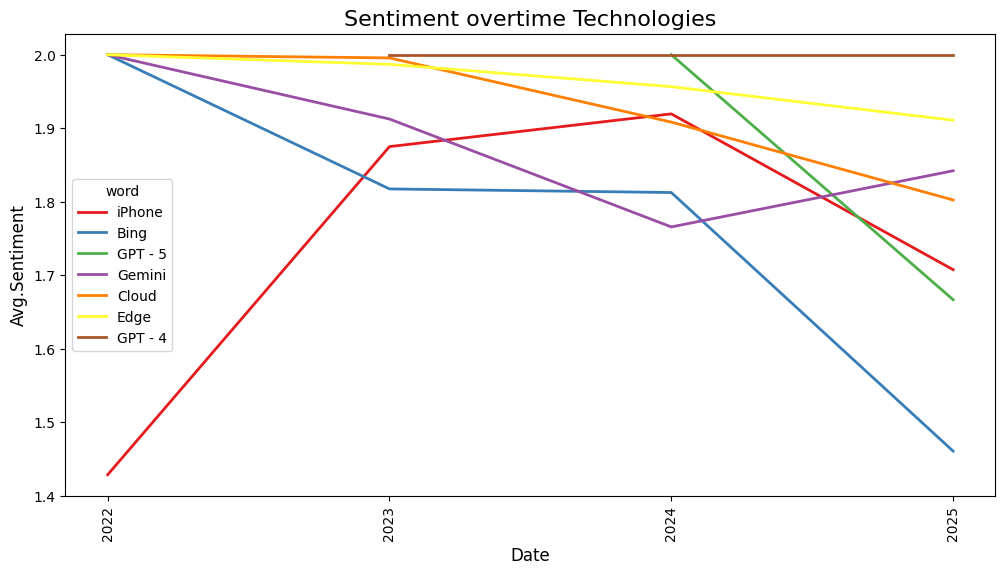

In [51]:
# Filter only ORG
df_aux = frenq_entities_year[frenq_entities_year['entity']=='ORG'].copy()
df_aux['word'] = df_aux['word'].str.replace('##vidia', 'Nvidia')
df_aux = df_aux.groupby(['word','entity','year']).agg({'frenqency':'sum','sentiment_topic':'mean'}).reset_index()
df_aux = df_aux.sort_values(by='frenqency', ascending=False)



# Remove noise entities
df_aux = df_aux[df_aux['word']!='##I']
df_aux = df_aux[df_aux['word']!='##t']
df_aux = df_aux[df_aux['word']!='the']
df_aux = df_aux[df_aux['word']!='##lot']
df_aux = df_aux[df_aux['word']!='##lot']
df_aux = df_aux[df_aux['word']!='##3']
df_aux = df_aux[df_aux['word']!='##T']
df_aux = df_aux[df_aux['word']!='Pi']
df_aux = df_aux[df_aux['word']!='In']
df_aux = df_aux[df_aux['word']!='##2']
df_aux = df_aux[df_aux['word']!='##VI']
df_aux = df_aux[df_aux['word']!='Co']
df_aux = df_aux[df_aux['word']!='So']
df_aux = df_aux[df_aux['word']!='Re']
df_aux.reset_index(drop=True, inplace=True)





# Filter list_entities
list_entities = ['Gemini','GPT - 5', 'GPT - 4','Cloud','iPhone','Bing','Edge']
#8	Nvidia	ORG	15313.0	1.855954
df_aux = df_aux[df_aux['word'].isin(list_entities)]
df_aux = df_aux[df_aux['year'] != 2026]
display(df_aux)

df_aux = df_aux.sort_values(by='sentiment_topic', ascending=True)

num_bars = len(df_aux['word'])
color_gradient = plt.cm.viridis(np.linspace(0, 1, num_bars))
plt.figure(figsize=(10, 6))
# Create the vertical bar plot with colors and a hatch pattern
# Plot
# 3. Create the plot
plt.figure(figsize=(12, 6)) # Set the figure size

# 4. Use Seaborn's lineplot
sns.lineplot(data=df_aux,
             x='year',
             y='sentiment_topic',
             hue='word',    # Differentiates the lines by color
             palette='Set1',
             linewidth=2)

# 5. Customize the chart
plt.title('Sentiment overtime Technologies', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Avg.Sentiment', fontsize=12)

# Rotate x-axis dates so they don't overlap
plt.xticks(rotation=90)
plt.xticks(year_list)

# 6. Display the plot
plt.show()


